In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def dist(a, b):
    return np.sqrt(np.sum((a-b)**2))

def dunn(X, labels):
    inside, outside = 0, float('inf')
    for i in range(len(X)):
        for j in range(i+1, len(X)):
            d = dist(X[i], X[j])
            if labels[i] == labels[j]:
                inside = max(inside, d)
            else:
                outside = min(outside, d)
    return outside/inside if inside > 0 else 0

def kmeans(X, k, initial=None):
    if initial is None:
        initial = np.random.choice(len(X), k, replace=False)
    centers = X[initial].copy().astype(float)
    history = []

    for step in range(100):
        labels = np.array([
            np.argmin([dist(p, c) for c in centers]) for p in X
        ])
        new = centers.copy()

        for i in range(k):
            if np.any(labels == i):
                new[i] = X[labels == i].mean(axis=0)

        sse = sum(dist(X[i], new[labels[i]])**2 for i in range(len(X)))
        history.append((new.copy(), labels.copy(), sse))

        if np.array_equal(new, centers):
            centers = new
            break
        centers = new

    # Reassign once to the final centroids
    labels = np.array([
        np.argmin([dist(p, c) for c in centers]) for p in X
    ])
    sse = sum(dist(X[i], centers[labels[i]])**2 for i in range(len(X)))
    return centers, labels, sse, len(history), history

# Q1(a): Dataset 1
X1 = np.array([
    [2,10],[2,5],[8,4],[5,8],
    [7,5],[6,4],[1,2],[4,9]
], float)
names1 = np.array(['A1','A2','A3','B1','B2','B3','C1','C2'])

c, lab, sse, steps, history = kmeans(X1, 3, [0,3,6])

print("Q1(a)")
for i, (centers, labels, error) in enumerate(history, 1):
    print("\nIteration", i, "\nCentroids:\n", centers)
    for j in range(3):
        print("Cluster", j+1, names1[labels == j])
    print("SSE:", round(error, 4))
print("Dunn Index:", round(dunn(X1, lab), 4))

# Load Iris directly with pandas; species is used only for evaluation
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"
iris = pd.read_csv(url, header=None).dropna()
X = iris.iloc[:, :4].to_numpy(dtype=float)
species = iris.iloc[:, 4].to_numpy()

# Q1(b): 10 runs with K=3
runs = []
best_sse = float('inf')

for r in range(10):
    c, lab, error, steps, hist = kmeans(X, 3)
    runs.append([r+1, error, dunn(X, lab), steps])
    if error < best_sse:
        best_sse = error
        best_c, best_lab = c.copy(), lab.copy()

print("\nQ1(b): 10 runs")
print(pd.DataFrame(runs, columns=[
    'Run','SSE','Dunn Index','Iterations'
]).round(4))

# Q1(c): Best run
print("\nQ1(c): Best SSE =", round(best_sse, 4))
print("Centroids:\n", best_c)
print(pd.crosstab(
    pd.Series(best_lab, name='Cluster'),
    pd.Series(species, name='Species')
))

# Q1(d): K=2,3,4,5; select lowest SSE from 10 runs
results = []
for k in [2,3,4,5]:
    best_error = float('inf')
    for r in range(10):
        c, lab, error, steps, hist = kmeans(X, k)
        if error < best_error:
            best_error = error
            best_di = dunn(X, lab)
    results.append([k, best_error, best_di])

result = pd.DataFrame(results, columns=['K','SSE','Dunn Index'])
print("\nQ1(d)")
print(result.round(4))
print("Best K by Dunn index:",
      int(result.loc[result['Dunn Index'].idxmax(), 'K']))


Q1(a)

Iteration 1 
Centroids:
 [[ 2.  10. ]
 [ 6.   6. ]
 [ 1.5  3.5]]
Cluster 1 ['A1']
Cluster 2 ['A3' 'B1' 'B2' 'B3' 'C2']
Cluster 3 ['A2' 'C1']
SSE: 37.0

Iteration 2 
Centroids:
 [[3.   9.5 ]
 [6.5  5.25]
 [1.5  3.5 ]]
Cluster 1 ['A1' 'C2']
Cluster 2 ['A3' 'B1' 'B2' 'B3']
Cluster 3 ['A2' 'C1']
SSE: 23.25

Iteration 3 
Centroids:
 [[3.66666667 9.        ]
 [7.         4.33333333]
 [1.5        3.5       ]]
Cluster 1 ['A1' 'B1' 'C2']
Cluster 2 ['A3' 'B2' 'B3']
Cluster 3 ['A2' 'C1']
SSE: 14.3333

Iteration 4 
Centroids:
 [[3.66666667 9.        ]
 [7.         4.33333333]
 [1.5        3.5       ]]
Cluster 1 ['A1' 'B1' 'C2']
Cluster 2 ['A3' 'B2' 'B3']
Cluster 3 ['A2' 'C1']
SSE: 14.3333
Dunn Index: 1.0

Q1(b): 10 runs
   Run       SSE  Dunn Index  Iterations
0    1   78.9451      0.1094           3
1    2   78.9408      0.0988           4
2    3  145.2793      0.0300           5
3    4  142.8593      0.0538           7
4    5   78.9451      0.1094          10
5    6   78.9451      0.1094 

Proximity Matrix
       P1     P2     P3     P4     P5     P6
P1  0.000  0.707  5.657  3.606  4.243  3.202
P2  0.707  0.000  4.950  2.915  3.536  2.500
P3  5.657  4.950  0.000  2.236  1.414  2.500
P4  3.606  2.915  2.236  0.000  1.000  0.500
P5  4.243  3.536  1.414  1.000  0.000  1.118
P6  3.202  2.500  2.500  0.500  1.118  0.000

Q2(a): single
['P4'] + ['P6'] Distance: 0.5
['P1'] + ['P2'] Distance: 0.7071
['P5'] + ['P4', 'P6'] Distance: 1.0
['P3'] + ['P5', 'P4', 'P6'] Distance: 1.4142
['P1', 'P2'] + ['P3', 'P5', 'P4', 'P6'] Distance: 2.5

Q2(a): complete
['P4'] + ['P6'] Distance: 0.5
['P1'] + ['P2'] Distance: 0.7071
['P5'] + ['P4', 'P6'] Distance: 1.118
['P3'] + ['P5', 'P4', 'P6'] Distance: 2.5
['P1', 'P2'] + ['P3', 'P5', 'P4', 'P6'] Distance: 5.6569

Q2(a): average
['P4'] + ['P6'] Distance: 0.5
['P1'] + ['P2'] Distance: 0.7071
['P5'] + ['P4', 'P6'] Distance: 1.059
['P3'] + ['P5', 'P4', 'P6'] Distance: 2.0501
['P1', 'P2'] + ['P3', 'P5', 'P4', 'P6'] Distance: 3.8259
['P4'] + ['P6'] Dis

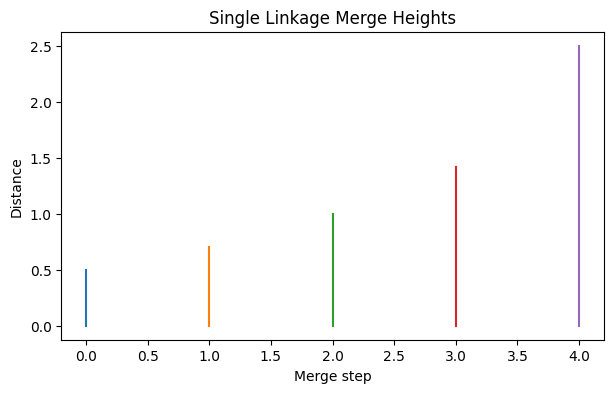

['P4'] + ['P6'] Distance: 0.5
['P1'] + ['P2'] Distance: 0.7071
['P5'] + ['P4', 'P6'] Distance: 1.118
['P3'] + ['P5', 'P4', 'P6'] Distance: 2.5
['P1', 'P2'] + ['P3', 'P5', 'P4', 'P6'] Distance: 5.6569


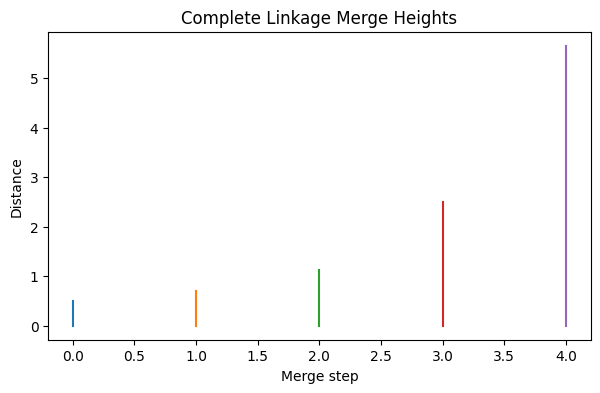

[9] + [34] Distance: 0.0
[37] + [9, 34] Distance: 0.0
[101] + [142] Distance: 0.0
[7] + [39] Distance: 0.1
[0] + [17] Distance: 0.1
[128] + [132] Distance: 0.1
[10] + [48] Distance: 0.1
[40] + [0, 17] Distance: 0.1414
[19] + [21] Distance: 0.1414
[4] + [40, 0, 17] Distance: 0.1414
[29] + [30] Distance: 0.1414
[57] + [93] Distance: 0.1414
[80] + [81] Distance: 0.1414
[116] + [137] Distance: 0.1414
[8] + [38] Distance: 0.1414
[46] + [19, 21] Distance: 0.1414
[3] + [47] Distance: 0.1414
[27] + [28] Distance: 0.1414
[49] + [7, 39] Distance: 0.1414
[82] + [92] Distance: 0.1414
[95] + [96] Distance: 0.1414
[127] + [138] Distance: 0.1414
[4, 40, 0, 17] + [49, 7, 39] Distance: 0.1414
[2] + [3, 47] Distance: 0.1414
[1] + [45] Distance: 0.1414
[12] + [1, 45] Distance: 0.1414
[63] + [91] Distance: 0.1414
[65] + [75] Distance: 0.1414
[99] + [95, 96] Distance: 0.1414
[27, 28] + [4, 40, 0, 17, 49, 7, 39] Distance: 0.1414
[69] + [80, 81] Distance: 0.1732
[123] + [126] Distance: 0.1732
[37, 9, 34] + [

In [6]:

# Q2: Agglomerative clustering from scratch

def agglomerative(X, names, method, stop=1):
    n = len(X)
    D = np.zeros((n,n))
    for i in range(n):
        for j in range(n):
            D[i,j] = dist(X[i], X[j])

    clusters = [[i] for i in range(n)]
    ids = list(range(n))
    merges = []

    while len(clusters) > stop:
        best = float('inf')
        pair = None

        for i in range(len(clusters)):
            for j in range(i+1, len(clusters)):
                ds = [D[a,b] for a in clusters[i] for b in clusters[j]]

                if method == 'single':
                    d = min(ds)
                elif method == 'complete':
                    d = max(ds)
                else:
                    d = np.mean(ds)

                if d < best:
                    best, pair = d, (i,j)

        i,j = pair
        a,b = clusters[i], clusters[j]

        print([names[x] for x in a], "+",
              [names[x] for x in b], "Distance:", round(best,4))

        merges.append([ids[i], ids[j], best, len(a)+len(b)])
        new_cluster = a+b
        new_id = n + len(merges)-1

        clusters.pop(j); clusters.pop(i)
        ids.pop(j); ids.pop(i)
        clusters.append(new_cluster)
        ids.append(new_id)

    return clusters, np.array(merges)

# Q2(a): Dataset 2 and proximity matrix
X2 = np.array([
    [1,1],[1.5,1.5],[5,5],
    [3,4],[4,4],[3,3.5]
], float)
names2 = ['P1','P2','P3','P4','P5','P6']

D = np.array([[dist(a,b) for b in X2] for a in X2])
print("Proximity Matrix")
print(pd.DataFrame(D, index=names2, columns=names2).round(3))

for method in ['single','complete','average']:
    print("\nQ2(a):", method)
    agglomerative(X2, names2, method)

# Q2(b): Dendrograms, drawn from manual merge history
for method in ['single','complete']:
    clusters, merges = agglomerative(X2, names2, method)
    plt.figure(figsize=(7,4))
    # Draw each merge height manually
    for i, row in enumerate(merges):
        left, right, height, size = row
        plt.plot([i, i], [0, height])
    plt.title(method.capitalize() + " Linkage Merge Heights")
    plt.xlabel("Merge step")
    plt.ylabel("Distance")
    plt.show()

# Q2(c): Iris species counts when 3 clusters remain
for method in ['single','complete','average']:
    clusters, merges = agglomerative(X, list(range(len(X))), method, stop=3)
    print("\nQ2(c):", method)
    for i, cluster in enumerate(clusters):
        print("Cluster", i+1,
              pd.Series(species[cluster]).value_counts().to_dict())


In [3]:

import numpy as np
import pandas as pd

X = np.array([
    [1,1], [2,1], [1,2], [2,2],
    [3,3], [6,5], [7,5], [7,6],
    [8,6], [9,7], [4,5], [9,1]
])
names = list("ABCDEFGHIJKL")

eps = 1.5
minpts = 3
labels = [-1]*len(X)
visited = [False]*len(X)
counts = []

# Find neighbours
for i in range(len(X)):
    near = []
    for j in range(len(X)):
        d = np.sqrt(np.sum((X[i]-X[j])**2))
        if d <= eps:
            near.append(j)
    counts.append(near)

cluster = 0

for i in range(len(X)):
    if visited[i]:
        continue

    visited[i] = True

    if len(counts[i]) < minpts:
        continue

    labels[i] = cluster
    queue = counts[i].copy()
    pos = 0

    while pos < len(queue):
        j = queue[pos]
        pos += 1

        if not visited[j]:
            visited[j] = True
            if len(counts[j]) >= minpts:
                for p in counts[j]:
                    if p not in queue:
                        queue.append(p)

        if labels[j] == -1:
            labels[j] = cluster

    cluster += 1

# Display results
types = []
for i in range(len(X)):
    if len(counts[i]) >= minpts:
        types.append("Core")
    elif labels[i] != -1:
        types.append("Border")
    else:
        types.append("Noise")

print(pd.DataFrame({
    'Point': names,
    'Points within Eps': [len(x) for x in counts],
    'Type': types,
    'Cluster': labels
}))


   Point  Points within Eps    Type  Cluster
0      A                  4    Core        0
1      B                  4    Core        0
2      C                  4    Core        0
3      D                  5    Core        0
4      E                  2  Border        0
5      F                  3    Core        1
6      G                  4    Core        1
7      H                  4    Core        1
8      I                  4    Core        1
9      J                  2  Border        1
10     K                  1   Noise       -1
11     L                  1   Noise       -1


K-Means SSE: 78.851441426146

 single
col_0   0   1   2
row_0            
0       0  50  48
1      50   0   0
2       0   0   2

 complete
col_0   0   1   2
row_0            
0       0  23  49
1      50   0   0
2       0  27   1

 average
col_0   0   1   2
row_0            
0       0  50  14
1      50   0   0
2       0   0  36

Clusters: 3
Noise points: 29



Q3: Eps = 1.5 MinPts = 3
   Point  Neighbour Count    Type  Cluster
0      A                4    Core        0
1      B                4    Core        0
2      C                4    Core        0
3      D                5    Core        0
4      E                2  Border        0
5      F                3    Core        1
6      G                4    Core        1
7      H                4    Core        1
8      I                4    Core        1
9      J                2  Border        1
10     K                1   Noise       -1
11     L                1   Noise       -1
Cluster 1 ['A' 'B' 'C' 'D' 'E']
Cluster 2 ['F' 'G' 'H' 'I' 'J']
Noise: ['K' 'L']

Q3: Eps = 0.9 MinPts = 3
   Point  Neighbour Count   Type  Cluster
0      A                1  Noise       -1
1      B                1  Noise       -1
2      C                1  Noise       -1
3      D                1  Noise       -1
4      E                1  Noise       -1
5      F                1  Noise       -1
6      G      

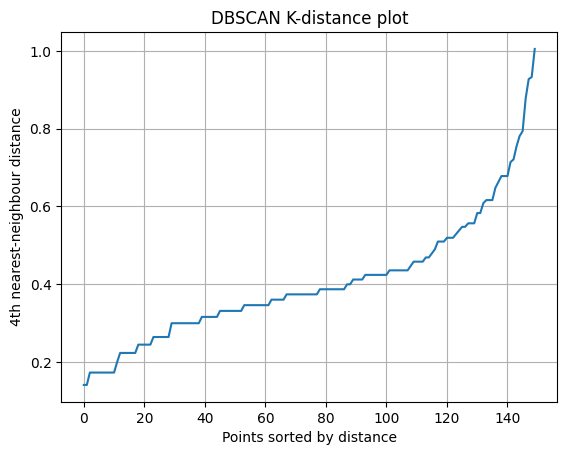

Enter Eps from the elbow of the plot:  0.6



Q3(d): Eps = 0.42
Number of clusters: 3
Noise points: 29
Cluster 1 {'Iris-setosa': 48}
Cluster 2 {'Iris-versicolor': 37}
Cluster 3 {'Iris-virginica': 33, 'Iris-versicolor': 3}

Q3(d): Eps = 0.6
Number of clusters: 2
Noise points: 9
Cluster 1 {'Iris-setosa': 49}
Cluster 2 {'Iris-versicolor': 46, 'Iris-virginica': 46}


In [7]:

# Q3: DBSCAN implemented from scratch

def dbscan(X, eps, minpts):
    n = len(X)
    near = []

    for i in range(n):
        near.append([
            j for j in range(n) if dist(X[i], X[j]) <= eps
        ])

    labels = np.full(n, -1)
    visited = np.zeros(n, dtype=bool)
    cluster = 0

    for i in range(n):
        if visited[i]:
            continue

        visited[i] = True
        if len(near[i]) < minpts:
            continue

        labels[i] = cluster
        queue = near[i].copy()
        pos = 0

        while pos < len(queue):
            j = queue[pos]
            pos += 1

            if not visited[j]:
                visited[j] = True
                if len(near[j]) >= minpts:
                    for p in near[j]:
                        if p not in queue:
                            queue.append(p)

            if labels[j] == -1:
                labels[j] = cluster

        cluster += 1

    types = []
    for i in range(n):
        if len(near[i]) >= minpts:
            types.append('Core')
        elif labels[i] != -1:
            types.append('Border')
        else:
            types.append('Noise')

    return labels, types, near

# Q3(a) and (b): Dataset 3
X3 = np.array([
    [1,1],[2,1],[1,2],[2,2],[3,3],[6,5],
    [7,5],[7,6],[8,6],[9,7],[4,5],[9,1]
], float)
names3 = np.array(list('ABCDEFGHIJKL'))

for eps, minpts in [(1.5,3),(0.9,3),(1.5,5),(2.3,3)]:
    labels, types, near = dbscan(X3, eps, minpts)
    print("\nQ3: Eps =", eps, "MinPts =", minpts)
    print(pd.DataFrame({
        'Point': names3,
        'Neighbour Count': [len(x) for x in near],
        'Type': types,
        'Cluster': labels
    }))
    for c in sorted(set(labels)-{-1}):
        print("Cluster", c+1, names3[labels == c])
    print("Noise:", names3[labels == -1])

# Q3(c): Sorted distance to 4th nearest neighbour
fourth = []
for i in range(len(X)):
    ds = sorted([dist(X[i], X[j])
                 for j in range(len(X)) if i != j])
    fourth.append(ds[3])

fourth = np.sort(fourth)
plt.plot(fourth)
plt.xlabel("Points sorted by distance")
plt.ylabel("4th nearest-neighbour distance")
plt.title("DBSCAN K-distance plot")
plt.grid()
plt.show()

eps_chosen = float(input("Enter Eps from the elbow of the plot: "))

# Q3(d): Iris DBSCAN results
for eps in [0.42, eps_chosen]:
    labels, types, near = dbscan(X, eps, 5)
    clusters = sorted(set(labels)-{-1})

    print("\nQ3(d): Eps =", eps)
    print("Number of clusters:", len(clusters))
    print("Noise points:", np.sum(labels == -1))

    for c in clusters:
        print("Cluster", c+1,
              pd.Series(species[labels == c]).value_counts().to_dict())


In [8]:

# Q4: Comparison using scikit-learn

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

# Q4(a): K-Means SSE
model = KMeans(n_clusters=3, n_init=10, random_state=42)
labels = model.fit_predict(X)

print("Q4(a): K-Means SSE =", model.inertia_)

# Q4(b): Agglomerative species counts
for method in ['single','complete','average']:
    model = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels = model.fit_predict(X)

    print("\nQ4(b):", method)
    print(pd.crosstab(
        pd.Series(labels, name='Cluster'),
        pd.Series(species, name='Species')
    ))

# Q4(c): DBSCAN
model = DBSCAN(eps=0.42, min_samples=5)
labels = model.fit_predict(X)

print("\nQ4(c): DBSCAN")
print("Number of clusters:", len(set(labels)-{-1}))
print("Noise points:", np.sum(labels == -1))

# Q4(d): Compare species counts for K-Means
model = KMeans(n_clusters=3, n_init=10, random_state=42)
labels = model.fit_predict(X)

print("\nQ4(d): K-Means species counts")
print(pd.crosstab(
    pd.Series(labels, name='Cluster'),
    pd.Series(species, name='Species')
))


Q4(a): K-Means SSE = 78.94084142614601

Q4(b): single
Species  Iris-setosa  Iris-versicolor  Iris-virginica
Cluster                                              
0                  0               50              48
1                 50                0               0
2                  0                0               2

Q4(b): complete
Species  Iris-setosa  Iris-versicolor  Iris-virginica
Cluster                                              
0                  0               23              49
1                 50                0               0
2                  0               27               1

Q4(b): average
Species  Iris-setosa  Iris-versicolor  Iris-virginica
Cluster                                              
0                  0               50              14
1                 50                0               0
2                  0                0              36

Q4(c): DBSCAN
Number of clusters: 3
Noise points: 29

Q4(d): K-Means species counts
Species  Iris-seto